# **BoxCar2D – Evolutionäre Algorithmen**

Dieses Notebook demonstriert das BoxCar2D Beispiel aus der Vorlesung. Für die Simulation wird die Physikengine Box2D eingesetzt, simuliert werden Chassis, Motoren, Rädern, Aufhängungen und Gelände. Die Simulation wird **live in einem eigenen Pygame-Fenster** angezeigt.

**Voraussetzung:** Der Jupyter-Kernel läuft **lokal auf einem Rechner mit grafischer Oberfläche**. Auch wenn Jupyter selbst im Browser angezeigt wird, öffnet sich Pygame als separates Fenster auf dem Rechner, auf dem der *Kernel* läuft. 

**Ablauf:** erst Genom und Operatoren verstehen → eine Probefahrt starten → mehrere Generationen evolvieren → bestes Fahrzeug beobachten → Übungsaufgabe.


## 0 · **Einrichtung**

Die Pakete werden nur im **aktuellen Jupyter-Kernel** installiert, wenn die Installationszelle ausgeführt wird. Eine bestehende Python-Version muss nicht gewechselt werden. Voraussetzung für das Live-Fenster ist eine lokale Desktop-Umgebung. Für dauerhaft konfliktfreie Lehrumgebungen sollten die Pakete idealerweise bereits installiert sein.

Falls die Pakete schon verfügbar sind, kann die nächste Zelle übersprungen werden.


%pip install "Box2D==2.3.10" "pygame>=2.5,<3" "matplotlib>=3.7"

## 1 · **Einstellungen und Aufbau des Genoms**
Wir übernehmen die Genom-Repräsentation aus dem Skript (acht Winkel, acht Längen, Radpositionen, Radwinkel, Radien und optionale Räder). Für das Notebook beginnen wir mit einer kleineren Population und kürzerer Bewertung, damit die erste Ausführung überschaubar bleibt.

In [ ]:
import math, random, sys, time, colorsys
from dataclasses import dataclass, field
from typing import List, Tuple, Optional

import pygame
from pygame import gfxdraw

from Box2D import (
    b2World, b2Vec2, b2PolygonShape, b2CircleShape,
    b2RevoluteJointDef
)

# -------------------- Anzeige & Physik --------------------
SCREEN_W, SCREEN_H = 1200, 720
PPM = 32.0
DT = 1.0 / 60.0
GRAVITY = b2Vec2(0, -10)

# -------------------- GA --------------------
POP_SIZE = 8
EVAL_TIME = 12.0
STEPS_PER_INDIVIDUAL = int(EVAL_TIME / DT)
ELITISM = 2
MUTATION_RATE = 0.1
TOURNAMENT_K = 3
RANDOM_SEED = 4242

# -------------------- Antrieb --------------------
MOTOR_SPEED = -30.0
MOTOR_TORQUE = 85.0

# -------------------- STARRE Aufhängung --------------------
ARM_EXTRA = 0.18  # L = wheel_radius + ARM_EXTRA (m)

# -------------------- Aufhängung nach Bruch --------------------
# 'chassis' = gelbe Linie bleibt am Chassis (Pivot->EndLocal)
# 'wheel'   = gelbe Linie bleibt am Rad (vom Rad aus feste Länge & eingefrorene Richtung)
# 'random'  = pro Bruch zufällig 'chassis' oder 'wheel'
ARM_STICK_MODE = 'wheel' #'random'

# -------------------- Räder --------------------
MAX_WHEELS = 4
MANDATORY_WHEELS = 2

# -------------------- Track --------------------
TRACK_START_X = -80.0
TRACK_LENGTH  = 1200.0
START_PLATFORM_TO = 30.0
BASE_Y = 0.0
STALL_TIME = 3.0

# -------------------- Kamera --------------------
CAMERA_FLOOR_MARGIN = 5.8
CAMERA_SMOOTH = 0.15
CAMERA_MIN_VISIBLE_Y = BASE_Y - 3.0

# -------------------- BREAK-LOGIK (Radgelenke) --------------------
BREAK_WHEEL_FORCE  = 900.0   # N
BREAK_WHEEL_TORQUE = 900.0   # N·m
BREAK_GRACE_STEPS  = 6       # Schritte über Schwelle bis Bruch

# -------------------- Genome --------------------
def r(a,b): return random.uniform(a,b)

@dataclass
class Genome:
    # Chassis
    angles: List[float] = field(default_factory=lambda:[r(0,2*math.pi) for _ in range(8)])
    mags:   List[float] = field(default_factory=lambda:[r(0.8,3.0)     for _ in range(8)])
    # Räder (Länge = MAX_WHEELS)
    wheel_vertex: List[int]   = field(default_factory=lambda:[random.randint(0,7) for _ in range(MAX_WHEELS)])
    axle_angle:   List[float] = field(default_factory=lambda:[r(0,2*math.pi)     for _ in range(MAX_WHEELS)])
    wheel_radius: List[float] = field(default_factory=lambda:[r(0.28,1.1)        for _ in range(MAX_WHEELS)])
    # Optional-Flags für Räder >= Pflicht
    wheel_enabled: List[bool] = field(default_factory=lambda:[
        True if i < MANDATORY_WHEELS else (random.random()<0.5)
        for i in range(MAX_WHEELS)
    ])

    def flat(self)->List[float]:
        enabled_floats = [1.0 if self.wheel_enabled[i] else 0.0 for i in range(MAX_WHEELS)]
        return ( self.angles
               + self.mags
               + list(map(float,self.wheel_vertex))
               + self.axle_angle
               + self.wheel_radius
               + enabled_floats )

    @staticmethod
    def from_flat(vals: List[float]) -> "Genome":
        g = Genome()
        i = 0
        g.angles = list(vals[i:i+8]); i += 8
        g.mags   = [max(0.2, min(4.0, v)) for v in vals[i:i+8]]; i += 8
        g.wheel_vertex = [int(round(v))%8 for v in vals[i:i+MAX_WHEELS]]; i += MAX_WHEELS
        g.axle_angle   = [v%(2*math.pi)  for v in vals[i:i+MAX_WHEELS]]; i += MAX_WHEELS
        g.wheel_radius = [max(0.1,min(1.5,v)) for v in vals[i:i+MAX_WHEELS]]; i += MAX_WHEELS
        flags = vals[i:i+MAX_WHEELS]
        en: List[bool] = []
        for w in range(MAX_WHEELS):
            en.append(True if w < MANDATORY_WHEELS else (flags[w] > 0.5))
        g.wheel_enabled = en
        return g

# Notebook-spezifisch: wenige Fahrzeuge zum Kennenlernen. Später erhöhen!
POP_SIZE = 8
EVAL_TIME = 8.0
STEPS_PER_INDIVIDUAL = int(EVAL_TIME / DT)
N_GENERATIONS = 30
random.seed(RANDOM_SEED)

pygame 2.6.1 (SDL 2.28.4, Python 3.13.18)
Hello from the pygame community. https://www.pygame.org/contribute.html


## 2 · **Mutation** – zufällige Veränderung einzelner Gene
Mit Wahrscheinlichkeit `p` wird jedes Gen neu gezogen; optionale Räder werden umgeschaltet. **Beobachten:** Warum werden die beiden Pflicht-Räder nicht deaktiviert?

In [2]:
def mutate(self, p=MUTATION_RATE):
        for i in range(8):
            if random.random()<p: self.angles[i] = r(0, 2*math.pi)
            if random.random()<p: self.mags[i]   = r(0.8, 3.0)
        for i in range(MAX_WHEELS):
            if random.random()<p: self.wheel_vertex[i] = random.randint(0,7)
            if random.random()<p: self.axle_angle[i]   = r(0, 2*math.pi)
            if random.random()<p: self.wheel_radius[i] = r(0.28, 1.1)
        for i in range(MANDATORY_WHEELS, MAX_WHEELS):
            if random.random()<p:
                self.wheel_enabled[i] = not self.wheel_enabled[i]

# Die Methode aus dem Originalskript an die Klasse binden (separate Lehrzelle).
Genome.mutate = mutate

## 3 · **Crossover** – Rekombination zweier Eltern
Der originale **2-Point-Crossover** tauscht einen zusammenhängenden Abschnitt der flachen Genliste zwischen beiden Eltern.

In [3]:
def two_point_crossover(a: Genome, b: Genome) -> Tuple[Genome, Genome]:
    A, B = a.flat(), b.flat()
    n = len(A)
    i, j = sorted(random.sample(range(1, n), 2))  # 1..n-1, i<j
    C = A[:i] + B[i:j] + A[j:]
    D = B[:i] + A[i:j] + B[j:]
    return Genome.from_flat(C), Genome.from_flat(D)

### Mutation und Crossover sichtbar machen
Die beiden folgenden Beispiele benötigen **keine** Physikberechnung.

In [4]:
elter_a, elter_b = Genome(), Genome()
kind_a, kind_b = two_point_crossover(elter_a, elter_b)
vorher = kind_a.flat().copy()
kind_a.mutate(p=0.3)
print("Anzahl Gene:", len(vorher))
print("Durch Mutation veränderte Gene:", sum(a != b for a, b in zip(vorher, kind_a.flat())))
print("Erste zwölf Gene – vorher:", [round(x,2) for x in vorher[:12]])
print("Erste zwölf Gene – nachher:", [round(x,2) for x in kind_a.flat()[:12]])

Anzahl Gene: 32
Durch Mutation veränderte Gene: 7
Erste zwölf Gene – vorher: [5.42, 2.61, 0.18, 2.45, 2.02, 1.16, 3.1, 3.84, 2.8, 1.86, 2.82, 2.74]
Erste zwölf Gene – nachher: [5.42, 2.61, 0.18, 2.45, 2.02, 1.16, 3.1, 3.84, 2.8, 1.85, 2.82, 1.68]


## 4 · **Box2D-Physik – Strecke und Fahrzeuge**


In [5]:
# -------------------- Farben aus Genom --------------------
def color_from_genome(gen: Genome):
    h=(sum(gen.angles)/(2*math.pi*8))%1.0
    s=0.55+0.35*((sum(m*m for m in gen.mags)%1.0)); v=0.88
    r1,g1,b1=colorsys.hsv_to_rgb(h,s,v)
    r2,g2,b2=colorsys.hsv_to_rgb((h+0.05)%1.0,min(1.0,s*0.9),0.5)
    r3,g3,b3=colorsys.hsv_to_rgb((h+0.12)%1.0,s*0.8,0.65)
    to255=lambda x:max(0,min(255,int(round(x*255))))
    return (to255(r1),to255(g1),to255(b1)),(to255(r2),to255(g2),to255(b2)),(to255(r3),to255(g3),to255(b3))

# -------------------- Strecke --------------------
def build_track(world, start=(0.0, BASE_Y)):
    ground = world.CreateStaticBody(position=start)
    segments = []
    x = TRACK_START_X
    dx = 2.0
    last = b2Vec2(x, BASE_Y)

    def h(xx):
        if xx <= START_PLATFORM_TO: return BASE_Y
        y = BASE_Y
        y += 3.0 * math.sin(xx * 0.055)
        y += 1.7 * math.sin(xx * 0.11 + 1.3)
        y += 0.9 * math.sin(xx * 0.21 + 2.1)
        return max(BASE_Y - 2.0, y)

    rnd = random.Random(42)
    cache = {}
    def noise(xx):
        k = int(xx*10)
        if k not in cache: cache[k] = (rnd.random()-0.5)
        return cache[k]

    while x < TRACK_LENGTH:
        y = h(x) + 0.8 * noise(x)
        newp = b2Vec2(x, y)
        segments.append((last, newp))
        last = newp
        x += dx

    endp = b2Vec2(x+80.0, BASE_Y)
    segments.append((last, endp))

    for a, b in segments:
        ground.CreateEdgeFixture(vertices=[a,b], friction=1.0, restitution=0.0)
    return ground, segments

def y_on_track(segments: List[Tuple[b2Vec2,b2Vec2]], x: float) -> float:
    for a,b in segments:
        xa, xb = a.x, b.x
        if (xa <= x <= xb) or (xb <= x <= xa):
            if xb != xa:
                t = (x - xa) / (xb - xa)
                return a.y + t * (b.y - a.y)
            return a.y
    return BASE_Y

# -------------------- Fahrzeug --------------------
class Car:
    def __init__(self, world, genome: Genome, base_pos: b2Vec2):
        self.world = world
        self.genome = genome
        self.base_pos = base_pos
        self.color_fill, self.color_outline, self.color_wheel = color_from_genome(genome)
        self.max_x = 0.0
        self._build()

    def _build(self):
        g = self.genome

        # Chassis aus 8 Dreiecken
        pts = [b2Vec2(g.mags[i]*math.cos(g.angles[i]), g.mags[i]*math.sin(g.angles[i])) for i in range(8)]
        order = sorted(range(8), key=lambda i: math.atan2(pts[i].y, pts[i].x))
        pts = [pts[i] for i in order]

        self.chassis = self.world.CreateDynamicBody(position=self.base_pos, angularDamping=1.0, linearDamping=0.05)
        for i in range(8):
            a, b = pts[i], pts[(i+1)%8]
            self.chassis.CreateFixture(shape=b2PolygonShape(vertices=[b2Vec2(0,0), a, b]),
                                       density=1.2, friction=0.7)
        self.vertices_local = pts

        # Arrays
        self.wheels: List[Tuple[Optional[object], Optional[object]]] = []
        self.pivot_locals: List[b2Vec2] = []
        self.end_locals:   List[b2Vec2] = []
        self.enabled_mask: List[bool] = []
        self.break_counter: List[int]  = []

        # Neu für "kleben":
        self.arm_broken: List[bool]    = []
        self.arm_dir_world: List[b2Vec2] = []
        self.arm_len: List[float]      = []
        self.arm_mode: List[str]       = []  # 'chassis' oder 'wheel' – pro Rad nach Bruch fix

        for i in range(MAX_WHEELS):
            enabled = (i < MANDATORY_WHEELS) or g.wheel_enabled[i]
            enabled = bool(enabled)
            self.enabled_mask.append(enabled)
            self.break_counter.append(0)

            # Defaults
            self.arm_broken.append(False)
            self.arm_dir_world.append(b2Vec2(1,0))
            self.arm_len.append(0.0)
            self.arm_mode.append('chassis')

            radius = g.wheel_radius[i]
            if (not enabled) or radius <= 0:
                self.wheels.append((None, None))
                self.pivot_locals.append(b2Vec2(0,0))
                self.end_locals.append(b2Vec2(0,0))
                self.arm_len[-1] = 0.0
                continue

            pivot_local = self.vertices_local[g.wheel_vertex[i]]
            theta = g.axle_angle[i]
            L = radius + ARM_EXTRA

            end_local = b2Vec2(pivot_local.x + L*math.cos(theta),
                               pivot_local.y + L*math.sin(theta))
            end_world = self.chassis.GetWorldPoint(end_local)

            wheel = self.world.CreateDynamicBody(position=end_world, angularDamping=0.1, linearDamping=0.0)
            wheel.CreateFixture(shape=b2CircleShape(radius=radius), density=1.0, friction=1.9)

            rj = b2RevoluteJointDef()
            rj.Initialize(self.chassis, wheel, end_world)
            rj.enableMotor = True
            rj.motorSpeed = MOTOR_SPEED
            rj.maxMotorTorque = MOTOR_TORQUE
            rev = self.world.CreateJoint(rj)

            self.wheels.append((wheel, rev))
            self.pivot_locals.append(pivot_local)
            self.end_locals.append(end_local)
            self.arm_len[-1] = L

    def step(self, dt):
        self.max_x = max(self.max_x, self.chassis.position.x)

        # Bruchprüfung
        inv_dt = 1.0 / dt if dt > 0 else 0.0
        for i, ((wheel, rev), enabled) in enumerate(zip(self.wheels, self.enabled_mask)):
            if not enabled or (wheel is None) or (rev is None):
                continue
            F = rev.GetReactionForce(inv_dt)
            T = rev.GetReactionTorque(inv_dt)
            Fmag = math.hypot(F.x, F.y)

            if (Fmag > BREAK_WHEEL_FORCE) or (abs(T) > BREAK_WHEEL_TORQUE):
                self.break_counter[i] += 1
            else:
                self.break_counter[i] = max(0, self.break_counter[i]-1)

            if self.break_counter[i] >= BREAK_GRACE_STEPS:
                # Gelenk reißt
                try:
                    self.world.DestroyJoint(rev)
                except:
                    pass

                # Modus festlegen und merken
                mode = ARM_STICK_MODE
                if mode == 'random':
                    mode = random.choice(['wheel','chassis'])
                self.arm_mode[i] = mode
                self.arm_broken[i] = True

                if mode == 'wheel':
                    # Richtung vom Pivot zum Rad im Bruchmoment einfrieren (Welt)
                    pivot_world = self.chassis.GetWorldPoint(self.pivot_locals[i])
                    dir_w = b2Vec2(wheel.position.x - pivot_world.x,
                                   wheel.position.y - pivot_world.y)
                    ln = math.hypot(dir_w.x, dir_w.y)
                    if ln > 1e-6:
                        dir_w *= (1.0 / ln)
                    else:
                        dir_w = b2Vec2(1,0)
                    self.arm_dir_world[i] = dir_w
                # bei 'chassis' genügt end_locals (lokal) + L

                # Rad bleibt frei rollend erhalten
                self.wheels[i] = (wheel, None)
                wheel.angularDamping = 0.02
                self.break_counter[i] = 0

    def destroy(self):
        for (wheel, rev) in self.wheels:
            if rev:
                try: self.world.DestroyJoint(rev)
                except: pass
            if wheel:
                try: self.world.DestroyBody(wheel)
                except: pass
        if self.chassis:
            try: self.world.DestroyBody(self.chassis)
            except: pass

## 5 · **Selektion und Elitismus**
**Turnierselektion:** Aus `k` zufällig gewählten Fahrzeugen gewinnt das mit der höchsten Fitness. **Elitismus:** Die besten `ELITISM` Fahrzeuge werden direkt übernommen. Danach entstehen Kinder durch Crossover und Mutation.

In [6]:
# -------------------- GA --------------------
def tournament_select(pop, fit, k=TOURNAMENT_K):
    ids = random.sample(range(len(pop)), k)
    best = max(ids, key=lambda i: fit[i])
    return pop[best]

def evolve(pop, fit):
    ranked = [g for g,_ in sorted(zip(pop, fit), key=lambda x: x[1], reverse=True)]
    new_pop = ranked[:ELITISM]
    while len(new_pop) < len(pop):
        p1 = tournament_select(pop, fit)
        p2 = tournament_select(pop, fit)
        c1, c2 = two_point_crossover(p1, p2)
        c1.mutate(MUTATION_RATE); c2.mutate(MUTATION_RATE)
        new_pop += [c1, c2]
    return new_pop[:len(pop)], ranked[0]

## 6 · **Darstellung im Pygame-Fenster**

Die folgenden Funktionen implementieren die Darstellung: mitlaufende Kamera, Räder, gelbe Aufhängung und Rekordfahne. Mit **SPACE** kann pausiert werden, mit **F** wird die beschleunigte Darstellung umgeschaltet, und **ESC** beendet den laufenden Test. Das Fenster bitte nicht während einer Notebook-Berechnung mehrfach starten.


In [7]:
# -------------------- Zeichnen --------------------
def w2s(v: b2Vec2, cam_x: float, cam_y: float) -> Tuple[int,int]:
    return int((v.x - cam_x) * PPM + 200), int(SCREEN_H - (v.y - cam_y) * PPM)

def draw_track(screen, body, cam_x, cam_y):
    for f in body.fixtures:
        v1, v2 = f.shape.vertices
        p1 = w2s(body.GetWorldPoint(v1), cam_x, cam_y)
        p2 = w2s(body.GetWorldPoint(v2), cam_x, cam_y)
        pygame.draw.line(screen, (100,100,100), p1, p2, 3)

def draw_car(screen, car: Car, cam_x, cam_y):
    ang = car.chassis.angle
    pos = car.chassis.position
    fill = car.color_fill
    outline = car.color_outline

    # Chassis
    pts_world = []
    for v in car.vertices_local:
        x = v.x*math.cos(ang) - v.y*math.sin(ang) + pos.x
        y = v.x*math.sin(ang) + v.y*math.cos(ang) + pos.y
        pts_world.append(w2s(b2Vec2(x,y), cam_x, cam_y))
    center = w2s(pos, cam_x, cam_y)
    n = len(pts_world)
    for i in range(n):
        a = pts_world[i]; b = pts_world[(i+1)%n]
        pygame.draw.polygon(screen, fill, [center, a, b], 0)
        pygame.draw.polygon(screen, outline, [center, a, b], 1)

    # Räder + gelbe Linie (gelb im Vordergrund)
    for i, ((wheel, _), enabled) in enumerate(zip(car.wheels, car.enabled_mask)):
        if not enabled or not wheel:
            continue
        # Rad zeichnen (hinten)
        p = w2s(wheel.position, cam_x, cam_y)
        r_pix = int(wheel.fixtures[0].shape.radius * PPM)
        gfxdraw.filled_circle(screen, p[0], p[1], r_pix, car.color_wheel)
        gfxdraw.aacircle(screen, p[0], p[1], r_pix, (25,25,25))
        ang_w = wheel.angle
        for k in range(6):
            a0 = ang_w + 2*math.pi*k/6
            dx = int(math.cos(a0)*r_pix*0.9)
            dy = int(math.sin(a0)*r_pix*0.9)
            pygame.draw.line(screen, (10,10,10), (p[0], p[1]), (p[0]+dx, p[1]-dy), 2)

        # GELBE Linie zuletzt – mit Sticky-Modus ohne Verlängern
        pivot_world = car.chassis.GetWorldPoint(car.pivot_locals[i])

        if car.arm_broken[i]:
            mode = car.arm_mode[i]
            if mode == 'chassis':
                # bleibt am Chassis: Pivot -> fixer Endpunkt (lokal) transformiert
                end_world = car.chassis.GetWorldPoint(car.end_locals[i])
                pygame.draw.line(screen, (255,220,60),
                                 w2s(pivot_world, cam_x, cam_y),
                                 w2s(end_world,  cam_x, cam_y), 4)
            else:  # 'wheel'
                # bleibt am Rad: vom Rad aus in eingefrorener Richtung, konstante Länge
                L = car.arm_len[i]
                dir_w = car.arm_dir_world[i]
                end2 = b2Vec2(wheel.position.x - dir_w.x * L,
                              wheel.position.y - dir_w.y * L)
                pygame.draw.line(screen, (255,220,60),
                                 w2s(end2,          cam_x, cam_y),
                                 w2s(wheel.position,cam_x, cam_y), 4)
        else:
            # intakt: Pivot -> aktuelles Radzentrum (Joint-Anker)
            pygame.draw.line(screen, (255,220,60),
                             w2s(pivot_world,    cam_x, cam_y),
                             w2s(wheel.position, cam_x, cam_y), 4)

# --- Best-Icon (mit Speichen & gelber Linie IM VORDERGRUND, skaliert inkl. Räder) ---
def draw_best_icon(surface: pygame.Surface, genome: Genome, rect: pygame.Rect):
    fill, outline, wheel_col = color_from_genome(genome)

    # Chassis-Punkte (lokal, konvexer Fächer um (0,0))
    pts = [b2Vec2(genome.mags[i]*math.cos(genome.angles[i]),
                  genome.mags[i]*math.sin(genome.angles[i])) for i in range(8)]
    order = sorted(range(8), key=lambda i: math.atan2(pts[i].y, pts[i].x))
    pts = [pts[i] for i in order]

    # Bounds inkl. (aktivierte) Räder/Arme
    all_pts = pts[:]
    for wi in range(MAX_WHEELS):
        enabled = (wi < MANDATORY_WHEELS) or genome.wheel_enabled[wi]
        if not enabled:
            continue
        v_id = genome.wheel_vertex[wi] % 8
        pivot = pts[v_id]
        theta = genome.axle_angle[wi]
        r = max(0.1, min(1.5, genome.wheel_radius[wi]))
        L = r + ARM_EXTRA
        end_local = b2Vec2(pivot.x + L * math.cos(theta),
                           pivot.y + L * math.sin(theta))
        all_pts += [pivot, end_local]

    xs = [p.x for p in all_pts] + [0.0]
    ys = [p.y for p in all_pts] + [0.0]
    minx, maxx = min(xs), max(xs)
    miny, maxy = min(ys), max(ys)
    w = max(maxx - minx, 1e-6)
    h = max(maxy - miny, 1e-6)

    margin = 10
    scale = min((rect.width - 2*margin) / w, (rect.height - 2*margin) / h) * 0.9
    cx = rect.x + rect.width // 2
    cy = rect.y + rect.height // 2 + 5

    # ✅ Korrekte Zentrierung (fix): (miny + h/2) statt (miny*h/2)
    def to_icon(p):
        return (int(cx + (p.x - (minx + w/2)) * scale),
                int(cy - (p.y - (miny + h/2)) * scale))

    center = to_icon(b2Vec2(0, 0))
    poly = [to_icon(p) for p in pts]

    # Chassis (Dreiecks-Fächer)
    for i in range(len(poly)):
        a, b = poly[i], poly[(i+1) % len(poly)]
        pygame.draw.polygon(surface, fill, [center, a, b], 0)
        pygame.draw.polygon(surface, outline, [center, a, b], 1)

    # Räder zuerst, gelbe Aufhängung zuletzt (im Vordergrund)
    for wi in range(MAX_WHEELS):
        enabled = (wi < MANDATORY_WHEELS) or genome.wheel_enabled[wi]
        if not enabled:
            continue
        v_id = genome.wheel_vertex[wi] % 8
        pivot = pts[v_id]
        theta = genome.axle_angle[wi]
        r = max(0.1, min(1.5, genome.wheel_radius[wi]))
        L = r + ARM_EXTRA

        end_local = b2Vec2(pivot.x + L*math.cos(theta),
                           pivot.y + L*math.sin(theta))
        p_pivot = to_icon(pivot)
        p_wheel = to_icon(end_local)
        rpix = max(2, int(r * scale))

        # Rad (unten)
        gfxdraw.filled_circle(surface, p_wheel[0], p_wheel[1], rpix, wheel_col)
        gfxdraw.aacircle(surface, p_wheel[0], p_wheel[1], rpix, (20, 20, 20))
        for k in range(6):
            a0 = 2*math.pi*k/6
            dx = int(math.cos(a0)*rpix*0.7)
            dy = int(math.sin(a0)*rpix*0.7)
            pygame.draw.line(surface, (30, 30, 30),
                             (p_wheel[0], p_wheel[1]),
                             (p_wheel[0] + dx, p_wheel[1] - dy), 1)

        # GELBE Linie (oben)
        pygame.draw.line(surface, (255, 220, 60), p_pivot, p_wheel, 2)


# -------------------- Steuerung --------------------
class Controls:
    def __init__(self):
        self.running = True
        self.paused = False
        self.fast = False
    def handle_events(self) -> str | None:
        for event in pygame.event.get():
            if event.type == pygame.QUIT:
                self.running = False
                pygame.quit(); sys.exit(0)
            elif event.type == pygame.KEYDOWN:
                if event.key == pygame.K_ESCAPE:
                    self.running = False
                    pygame.quit(); sys.exit(0)
                elif event.key == pygame.K_SPACE:
                    self.paused = not self.paused
                    return 'abort'
                elif event.key == pygame.K_f:
                    self.fast = not self.fast
                    return 'abort'
        return None

# -------------------- Evaluation --------------------
def eval_individual(world, track_body, genome, drawer, controls: "Controls"):
    base_pos = b2Vec2(START_PLATFORM_TO - 10.0, 4.0)
    car = Car(world, genome, base_pos=base_pos)
    last_x = car.chassis.position.x
    stall = 0.0
    best_x = 0.0

    steps = 0
    while steps < STEPS_PER_INDIVIDUAL:
        action = controls.handle_events()
        if action == 'abort' or not controls.running:
            break
        world.Step(DT, 8, 3)
        car.step(DT)
        x = car.chassis.position.x
        best_x = max(best_x, x)
        if x > last_x + 0.1:
            stall = 0.0; last_x = x
        else:
            stall += DT
        if stall > STALL_TIME:
            break
        if drawer and not controls.fast:
            drawer.update(car, track_body)
        else:
            pygame.event.pump()
        steps += 1

    car.destroy()
    return best_x

# -------------------- Drawer/HUD + Rekord-Fahne --------------------
class Drawer:
    def __init__(self, screen, segments: List[Tuple[b2Vec2,b2Vec2]]):
        self.screen = screen
        self.cam_x = 0.0
        self.cam_y = BASE_Y
        self.info = {}
        self.best_genome_icon: Optional[Genome] = None
        self.segments = segments
        self.flag_x: Optional[float] = None

    def set_info(self, **kw): self.info.update(kw)
    def set_best_genome(self, g: Optional[Genome]): self.best_genome_icon = g
    def set_flag_x(self, x: float): self.flag_x = x

    def draw_flag(self, cam_x, cam_y):
        if self.flag_x is None: return
        x = self.flag_x
        y_ground = y_on_track(self.segments, x)
        pole_h = 2.2
        flag_w, flag_h = 1.4, 0.8
        pole_bottom = w2s(b2Vec2(x, y_ground), cam_x, cam_y)
        pole_top    = w2s(b2Vec2(x, y_ground + pole_h), cam_x, cam_y)
        pygame.draw.line(self.screen, (50,50,50), pole_bottom, pole_top, 4)

        flag_rect = pygame.Rect(0,0,int(flag_w*PPM), int(flag_h*PPM))
        flag_rect.topleft = (pole_top[0]+2, pole_top[1]-flag_rect.height//2)
        pygame.draw.rect(self.screen, (255,255,255), flag_rect)
        pygame.draw.rect(self.screen, (60,60,60), flag_rect, 1)

        font = pygame.font.SysFont("consolas", max(12, int(0.42*flag_h*PPM)))
        text_dh = font.render("DH", True, (200,20,20))
        text_bw = font.render("BW", True, (90,90,90))
        total_w = text_dh.get_width() + text_bw.get_width()
        x0 = flag_rect.centerx - total_w//2
        y0 = flag_rect.centery - text_dh.get_height()//2
        self.screen.blit(text_dh, (x0, y0))
        self.screen.blit(text_bw, (x0 + text_dh.get_width(), y0))

    def update(self, car: Car, track_body):
        self.cam_x = car.chassis.position.x
        target_y = max(CAMERA_MIN_VISIBLE_Y, car.chassis.position.y - CAMERA_FLOOR_MARGIN)
        self.cam_y = (1.0 - CAMERA_SMOOTH) * self.cam_y + CAMERA_SMOOTH * target_y

        self.screen.fill((245,245,245))
        # Raster
        for dx in range(-3, 8):
            x_line = int(((dx*10.0) - (self.cam_x % 10.0)) * PPM + 200)
            pygame.draw.line(self.screen, (230,230,230), (x_line, 0), (x_line, SCREEN_H), 1)

        draw_track(self.screen, track_body, self.cam_x, self.cam_y)
        self.draw_flag(self.cam_x, self.cam_y)

        draw_car(self.screen, car, self.cam_x, self.cam_y)

        font = pygame.font.SysFont("consolas", 18)
        bestx = self.info.get('bestx', 0.0)
        lines = [
            f"gen {self.info.get('gen',0):03d} | ind {self.info.get('ind',0)+1:02d}/{self.info.get('pop',0)}",
            f"best x: {bestx:6.1f} m   cur: {car.max_x:6.1f} m",
            "[SPACE]=pause  [F]=fast  [ESC]=quit"
        ]
        for i, s in enumerate(lines):
            self.screen.blit(font.render(s, True, (30,30,30)), (12, 8 + i*20))

        if self.best_genome_icon is not None:
            icon_rect = pygame.Rect(SCREEN_W - 180, 10, 160, 100)
            pygame.draw.rect(self.screen, (255,255,255), icon_rect, border_radius=8)
            pygame.draw.rect(self.screen, (210,210,210), icon_rect, width=1, border_radius=8)
            draw_best_icon(self.screen, self.best_genome_icon, icon_rect)
            label = pygame.font.SysFont("consolas", 16).render("Best of gen", True, (60,60,60))
            self.screen.blit(label, (icon_rect.x, icon_rect.bottom + 2))

        pygame.display.flip()



## 7 · **Probefahrt – Live-Simulation**

Starte die Zelle. Es öffnet sich ein eigenes Pygame-Fenster mit dem fahrenden Auto. Die Notebook-Zelle bleibt während der Fahrt beschäftigt. **SPACE** pausiert, **F** beschleunigt, **ESC** beendet. Beachte: Bei normalem Notebook im *Browser* funktioniert das nur, wenn der Kernel lokal läuft.


In [8]:
def fenster_starten():
    """Pygame auf dem Rechner des Jupyter-Kernels anzeigen."""
    import os
    if os.environ.get('SDL_VIDEODRIVER', '').lower() == 'dummy':
        raise RuntimeError('SDL_VIDEODRIVER=dummy: Kein grafisches Pygame-Fenster möglich. Bitte lokalen Desktop-Kernel verwenden und Kernel neu starten.')
    if not pygame.get_init():
        pygame.init()
    if not pygame.display.get_init():
        pygame.display.init()
    pygame.display.set_caption('BoxCar2D | SPACE Pause | F Schnell | ESC Beenden')
    return pygame.display.set_mode((SCREEN_W, SCREEN_H), pygame.RESIZABLE)


def _live_events(status):
    for event in pygame.event.get():
        if event.type == pygame.QUIT or (event.type == pygame.KEYDOWN and event.key == pygame.K_ESCAPE):
            status['quit'] = True
        elif event.type == pygame.KEYDOWN and event.key == pygame.K_SPACE:
            status['pause'] = not status['pause']
        elif event.type == pygame.KEYDOWN and event.key == pygame.K_f:
            status['fast'] = not status['fast']


def fahrzeug_live_bewerten(genom, world, track_body, drawer, status, *,
                           generation=0, index=0, anzahl=1, clock=None):
    """Dasselbe Fahrzeug-/Geländemodell, gesteuert und sichtbar im Pygame-Fenster."""
    car = Car(world, genom, base_pos=b2Vec2(START_PLATFORM_TO - 10.0, 4.0))
    last_x = car.chassis.position.x
    best_x = last_x
    stall = 0.0
    steps = 0
    drawer.set_info(gen=generation, ind=index, pop=anzahl)
    try:
        while steps < STEPS_PER_INDIVIDUAL and not status['quit']:
            _live_events(status)
            if status['quit']:
                break
            if status['pause']:
                # Weiter Events verarbeiten, solange pausiert
                if clock: clock.tick(30)
                continue
            world.Step(DT, 8, 3)
            car.step(DT)
            x = car.chassis.position.x
            best_x = max(best_x, x)
            if x > last_x + 0.1:
                last_x = x
                stall = 0.0
            else:
                stall += DT
            if stall > STALL_TIME:
                break
            if not status['fast'] or steps % 20 == 0:
                drawer.update(car, track_body)
            # Begrenzung auf 60 Frames/s
            #if clock and not status['fast']:
            #    clock.tick(60)
            steps += 1
        return best_x
    finally:
        car.destroy()


def probefahrt_live(genom=None):
    """Ein Fahrzeug sichtbar testen; Fitnesswert zurückgeben."""
    if genom is None:
        genom = Genome()
    screen = fenster_starten()
    world = b2World(gravity=GRAVITY, doSleep=True)
    ground, segments = build_track(world)
    drawer = Drawer(screen, segments)
    status = {'quit': False, 'pause': False, 'fast': False}
    try:
        score = fahrzeug_live_bewerten(genom, world, ground, drawer, status, clock=pygame.time.Clock())
        print(f'Fitness (maximale x-Position): {score:.2f} m')
        return score
    finally:
        pygame.display.quit()



In [9]:
test_genom = Genome()
fitness_test = probefahrt_live(test_genom)

Fitness (maximale x-Position): 101.15 m


## 8 · **Evolution live verfolgen**

Jedes Fahrzeug wird **sichtbar** bewertet; danach erzeugen **Selektion, 2-Point-Crossover, Mutation und Elitismus** eine neue Generation. Für die erste Vorführung sind Population und Generationenzahl bewusst klein. Mit **F** kann man Durchläufe beschleunigen.


In [15]:
def evolution_live(anzahl_generationen=N_GENERATIONS):
    """Originalphysik + sichtbare Fitnessbewertung aller Fahrzeuge."""
    random.seed(RANDOM_SEED)
    population = [Genome() for _ in range(POP_SIZE)]
    screen = fenster_starten()
    world = b2World(gravity=GRAVITY, doSleep=True)
    track_body, segments = build_track(world)
    drawer = Drawer(screen, segments)
    clock = pygame.time.Clock()
    status = {'quit': False, 'pause': False, 'fast': False}
    verlauf_best, verlauf_mittel = [], []
    bestes_genom, rekord = None, float('-inf')
    try:
        for generation in range(anzahl_generationen):
            fitness = []
            for idx, g in enumerate(population):
                if status['quit']: break
                drawer.set_flag_x(max(0.0, rekord))
                drawer.set_best_genome(bestes_genom)
                drawer.set_info(bestx=max(0.0, rekord))
                wert = fahrzeug_live_bewerten(g, world, track_body, drawer, status,
                   generation=generation, index=idx, anzahl=len(population), clock=clock)
                if status['quit']: break
                fitness.append(wert)
                if wert > rekord:
                    rekord = wert
                    bestes_genom = Genome.from_flat(g.flat())
            if status['quit'] or not fitness: break
            verlauf_best.append(max(fitness))
            verlauf_mittel.append(sum(fitness)/len(fitness))
            print(f'Generation {generation}: best={max(fitness):.2f} m, '
                  f'Mittel={sum(fitness)/len(fitness):.2f} m')
            if generation < anzahl_generationen - 1:
                population, _ = evolve(population, fitness)
        return bestes_genom, verlauf_best, verlauf_mittel
    finally:
        pygame.display.quit()

N_GENERATIONS = 30
bestes_genom, verlauf_best, verlauf_mittel = evolution_live(N_GENERATIONS)


Generation 0: best=61.50 m, Mittel=30.86 m
Generation 1: best=61.50 m, Mittel=30.79 m
Generation 2: best=94.40 m, Mittel=58.48 m
Generation 3: best=95.59 m, Mittel=66.72 m
Generation 4: best=104.23 m, Mittel=68.32 m


## 9 · **Fitnessentwicklung ansehen**

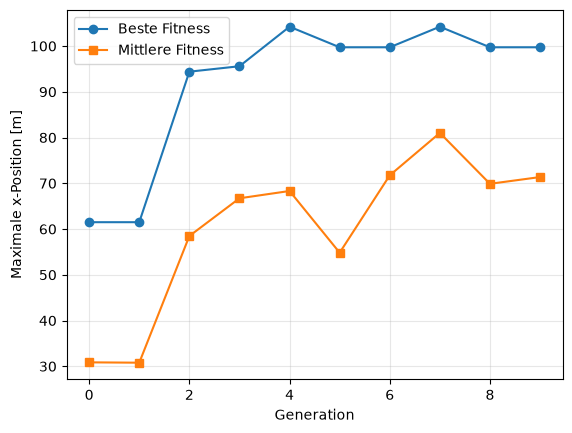

In [12]:
import matplotlib.pyplot as plt
if verlauf_best:
    plt.plot(verlauf_best, 'o-', label='Beste Fitness')
    plt.plot(verlauf_mittel, 's-', label='Mittlere Fitness')
    plt.xlabel('Generation')
    plt.ylabel('Maximale x-Position [m]')
    plt.grid(alpha=0.3)
    plt.legend()
    plt.show()
else:
    print('Es liegen noch keine vollständigen Generationen vor.')

## 10 · **Bestes Fahrzeug erneut fahren lassen**

Diese Zelle kann beliebig oft gestartet werden; sie öffnet erneut ein Pygame-Fenster.


In [13]:
if bestes_genom is not None:
    probefahrt_live(bestes_genom)
else:
    print('Bitte zuerst eine vollständige Evolution durchführen.')

Fitness (maximale x-Position): 104.23 m


## 11 · **Kleine Übungsaufgabe (10–15 Minuten)**

**Untersuchen Sie die Rolle der Mutationsrate.**

1. Notieren Sie die beste Fitness nach den ersten drei Generationen bei `MUTATION_RATE = 0.1`.
2. Ändern Sie `MUTATION_RATE` auf `0.02` und starten Sie **die Evolutionszelle** erneut. Vergleichen Sie die Kurven. Wiederholen Sie dies bei `0.3`.
3. Beschreiben Sie in zwei bis drei Sätzen: Warum kann eine sehr niedrige *und* eine sehr hohe Mutationsrate problematisch sein?

**Zusatz (optional):** Ändern Sie `TOURNAMENT_K` von 3 auf 2. Was erwarten Sie für den Selektionsdruck? Beobachten Sie, ob die kleine Stichprobe dazu passt.

**Wichtig:** Die Veränderung einer Konstanten in einer bereits ausgeführten Zelle wird erst durch **erneute Ausführung dieser Zelle** wirksam. Für Vergleiche führen Sie die Konfiguration und anschließend die Evolutionszelle erneut aus. Mit nur drei Generationen sind Beobachtungen zufallsabhängig und kein statistischer Nachweis.

---
